# 02 - Image branch

Trains the **image-only** RSL model on the 224x224 images produced by
`ImagePreprocessing.ipynb`.

MobileNetV3Small (ImageNet) is used as a **frozen** feature extractor. Because it never
updates, its pooled 576-d output is constant for a given image, so it is computed once and
cached - which turns training from hours of CPU convolutions into seconds and makes the
whole pipeline cheap to re-run.

In [1]:
import sys, warnings
sys.path.insert(0, "../scripts")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
import common as C, datasets as D, models as M
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 1. The cached backbone features

In [2]:
df, X, F, y, (tr, va, te) = D.load_all("blocked", "full")
print(f"backbone feature matrix: {F.shape}  (one 576-d row per image)")
print(f"train {tr.sum()}   val {va.sum()}   test {te.sum()}")

backbone feature matrix: (3067, 576)  (one 576-d row per image)
train 1882   val 268   test 271


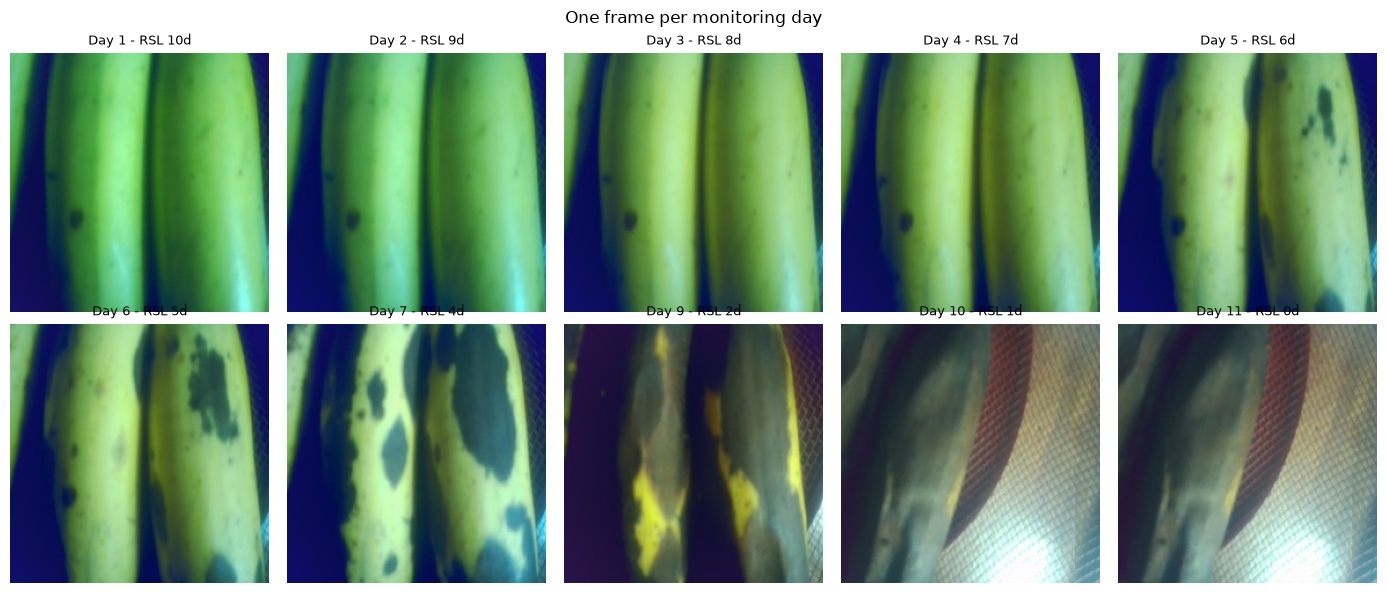

In [3]:
from PIL import Image
sample = df.groupby("Day").head(1).sort_values("Day")
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(C.IMAGE_DIR / r.image_file)); ax.axis("off")
    ax.set_title(f"Day {int(r.Day)} - RSL {r.RemainingShelfLife:.0f}d", fontsize=9)
for ax in axes.ravel()[len(sample):]:
    ax.axis("off")
plt.suptitle("One frame per monitoring day"); plt.tight_layout(); plt.show()

## 2. Head architecture

Only this head is trained. `image_embedding` (128-d) is what the fusion stage consumes;
`image_rsl` makes the branch a complete standalone model.

In [4]:
C.set_seeds()
head = M.compile_regressor(M.build_image_head(F.shape[1]))
head.summary()

Model: "image_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ backbone_features (InputLayer)  │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_dense_1 (Dense)           │ (None, 256)            │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_bn_1 (BatchNormalization) │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_drop_1 (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_embedding (Dense)         │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_rsl (Dense)               │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 181,761 (710.00 KB)

 Trainable params: 181,249 (708.00 KB)

 Non-trainable params: 512 (2.00 KB)

stopped after 47 epochs


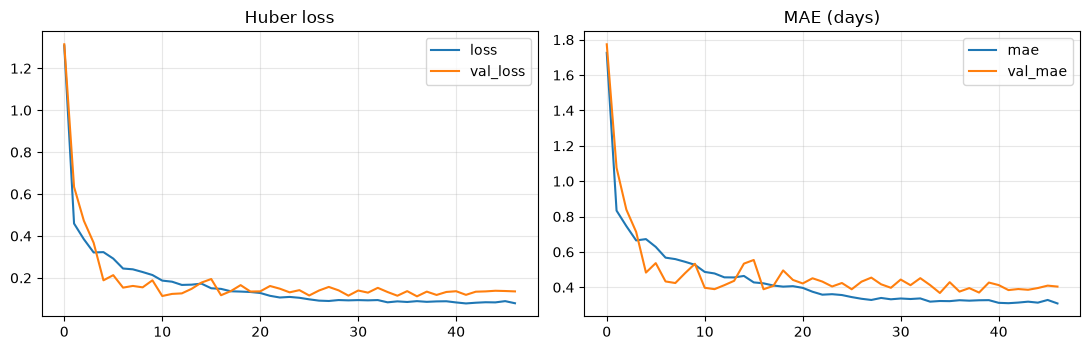

In [5]:
history = head.fit(
    F[tr], y[tr], validation_data=(F[va], y[va]),
    epochs=200, batch_size=64, callbacks=M.default_callbacks(), verbose=0,
)
print(f"stopped after {len(history.history['loss'])} epochs")
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Huber loss"); ax[0].grid(alpha=.3)
h[["mae", "val_mae"]].plot(ax=ax[1], title="MAE (days)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. Held-out performance

In [6]:
for part, mask in [("train", tr), ("val", va), ("test", te)]:
    m = C.regression_metrics(y[mask], head.predict(F[mask], verbose=0))
    print(f"{part:>5}  MAE {m['MAE']:.3f}  RMSE {m['RMSE']:.3f}  R2 {m['R2']:.4f}")

train  MAE 0.160  RMSE 0.205  R2 0.9912
  val  MAE 0.368  RMSE 0.479  R2 0.9296
 test  MAE 0.168  RMSE 0.426  R2 0.9475


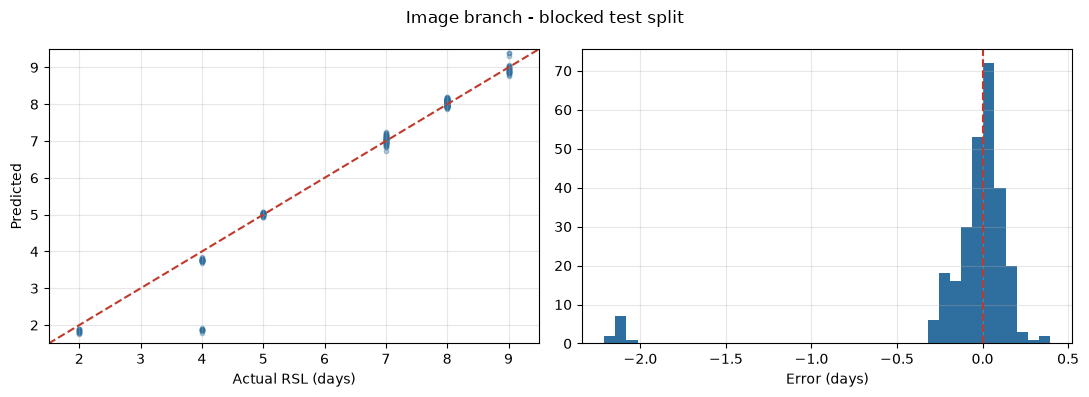

In [7]:
pred = head.predict(F[te], verbose=0).ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y[te], pred, s=10, alpha=.35, color="#2f6f9f")
lims = [y[te].min()-.5, y[te].max()+.5]
ax[0].plot(lims, lims, "--", color="#c0392b"); ax[0].set_xlim(lims); ax[0].set_ylim(lims)
ax[0].set_xlabel("Actual RSL (days)"); ax[0].set_ylabel("Predicted"); ax[0].grid(alpha=.3)
ax[1].hist(pred - y[te], bins=40, color="#2f6f9f"); ax[1].axvline(0, color="#c0392b", ls="--")
ax[1].set_xlabel("Error (days)"); ax[1].grid(alpha=.3)
plt.suptitle("Image branch - blocked test split"); plt.tight_layout(); plt.show()

## 4. Worst cases

Worth a look before the viva: the frames the image branch gets most wrong are the ones to
be able to explain.

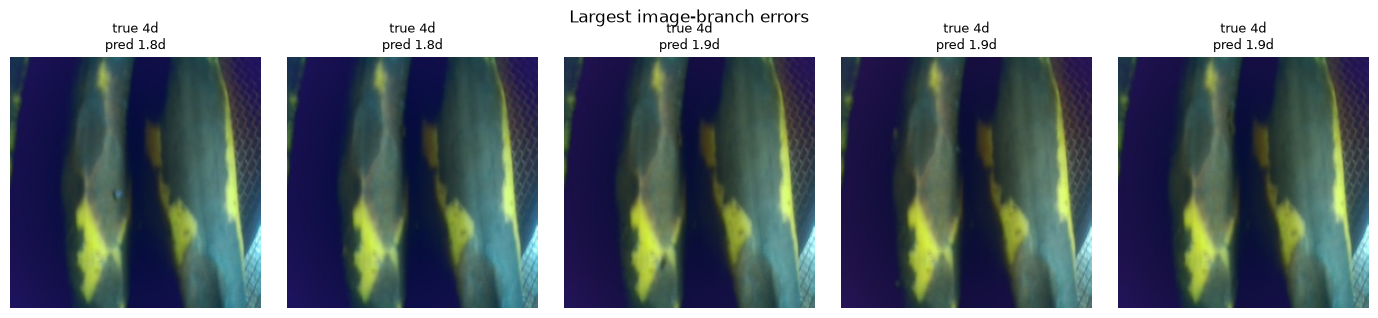

In [8]:
err = np.abs(pred - y[te])
worst = df.loc[te].assign(pred=pred, err=err).nlargest(5, "err")
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
for ax, (_, r) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(C.IMAGE_DIR / r.image_file)); ax.axis("off")
    ax.set_title(f"true {r.RemainingShelfLife:.0f}d\npred {r.pred:.1f}d", fontsize=9)
plt.suptitle("Largest image-branch errors"); plt.tight_layout(); plt.show()